In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, QuantileRegressor
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             mean_absolute_error, precision_recall_curve, r2_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
BASE = Path.cwd()

ALPHA = 0.05
SEED = 42
RNG = np.random.default_rng(SEED)

GREEN, GREY, DARK, RED, GRID = "#5A9F62", "#A6A6A6", "#1F1F1F", "#B45E4D", "#E3E3E3"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "font.size": 10})

In [4]:
df = pd.read_csv("startup_funding_clean.csv", parse_dates=["funding_date"])
d = df[df["amount_disclosed"] == 1].copy()          # deals with a known amount
d["log_amount"] = np.log10(d["amount_usd"])
d["large_deal"] = (d["amount_usd"] >= 5e6).astype(int)

In [6]:
# group rare categories so every group has enough rows for testing/modelling
top_cities = d.loc[d["city"] != "Unknown", "city"].value_counts().head(8).index
d["city_grp"] = np.where(d["city"].isin(top_cities), d["city"], "Other")
d["stage_grp"] = d["funding_stage"].replace({
    "Series A": "Series A-C", "Series B": "Series A-C", "Series C": "Series A-C",
    "Pre-Series A": "Seed / Angel", "Other (Venture / Corporate / Bridge)": "Other", "Unknown": "Other"})
d["sector_grp"] = d["sector"].replace({"Unknown": "Others"})
d["syndicate"] = np.where(d["investor_count"] >= 2, "B: 2+ investors", "A: 1 investor")
d.loc[d["investor_count"] == 0, "syndicate"] = np.nan
d["hub"] = np.where(d["city"] == "Bengaluru", "B: Bengaluru", "A: Rest of India")
d.loc[d["city"] == "Unknown", "hub"] = np.nan

print(f"Deals: {len(df):,} | disclosed amounts used for size analysis: {len(d):,} "
    f"({len(d)/len(df):.1%}) | period {df['funding_date'].min()} - {df['funding_date'].max()}")

Deals: 3,043 | disclosed amounts used for size analysis: 2,072 (68.1%) | period 01-01-2016 - 31-10-2017


### 1. DISTRIBUTION CHECKS & BOOTSTRAP CONFIDENCE INTERVALS

raw amount    skew= 17.61  kurtosis=  413.63  D'Agostino p=0.0e+00  Shapiro(n=500) W=0.227 p=4.7e-41
log10 amount  skew=  0.26  kurtosis=   -0.28  D'Agostino p=9.9e-08  Shapiro(n=500) W=0.987 p=2.2e-04
-> Raw amounts are extremely right-skewed. log10 makes them close to symmetric, so
   parametric tests below use log10(amount); non-parametric tests use raw amounts.

Bootstrap 95% CI of the median deal (USD M), 5,000 resamples:
  2015: n= 653  median=$  1.50M  CI [$1.00M, $2.00M]
  2016: n= 586  median=$  1.00M  CI [$0.75M, $1.00M]
  2017: n= 456  median=$  2.25M  CI [$1.50M, $3.00M]
  2018: n= 265  median=$  4.00M  CI [$3.00M, $5.00M]
  2019: n= 105  median=$ 12.00M  CI [$6.00M, $19.00M]


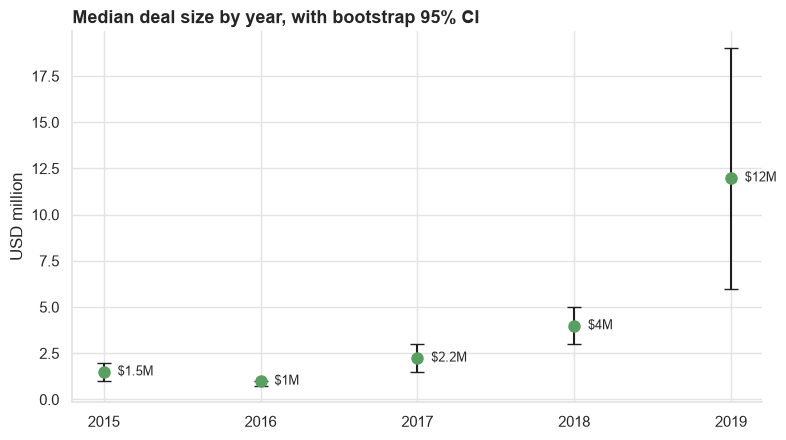

In [7]:
for label, x in [("raw amount", d["amount_usd"]), ("log10 amount", d["log_amount"])]:
    k2, p = stats.normaltest(x)
    sh_w, sh_p = stats.shapiro(x.sample(500, random_state=SEED))
    print(f"{label:<13} skew={x.skew():6.2f}  kurtosis={x.kurt():8.2f}  "
        f"D'Agostino p={p:.1e}  Shapiro(n=500) W={sh_w:.3f} p={sh_p:.1e}")
print("-> Raw amounts are extremely right-skewed. log10 makes them close to symmetric, so")
print("   parametric tests below use log10(amount); non-parametric tests use raw amounts.")


print("\nBootstrap 95% CI of the median deal (USD M), 5,000 resamples:")
ci_rows = []
for yr, g in d[d["year"] <= 2019].groupby("year"):
    bootstrap_values = g["amount_usd_mn"].to_numpy()
    bootstrap_samples = RNG.choice(bootstrap_values, (5000, len(bootstrap_values)), replace=True)
    bootstrap_medians = np.median(bootstrap_samples, axis=1)
    lo, hi = np.percentile(bootstrap_medians, [2.5, 97.5])
    ci_rows.append((yr, g["amount_usd_mn"].median(), lo, hi))
    print(f"  {yr}: n={len(g):4d}  median=${g['amount_usd_mn'].median():6.2f}M  CI [${lo:.2f}M, ${hi:.2f}M]")

ci = pd.DataFrame(ci_rows, columns=["year", "median", "lo", "hi"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(ci["year"], ci["median"], yerr=[ci["median"] - ci["lo"], ci["hi"] - ci["median"]],
            fmt="o", color=GREEN, ecolor=DARK, capsize=5, markersize=8, linewidth=1.5)
for _, r in ci.iterrows():
    ax.annotate(f"${r['median']:.2g}M", (r["year"], r["median"]), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.set_title("Median deal size by year, with bootstrap 95% CI")
ax.set_ylabel("USD million")
ax.set_xticks(ci["year"])
fig.tight_layout()
plt.show()

### 2. HYPOTHESIS TESTS

In [8]:
# --- 2.1 Welch t-test + Mann-Whitney: Bengaluru vs Mumbai
blr = d.loc[d["city"] == "Bengaluru"]
mum = d.loc[d["city"] == "Mumbai"]
t, p = stats.ttest_ind(blr["log_amount"], mum["log_amount"], equal_var=False)
pooled = np.sqrt((blr["log_amount"].var() + mum["log_amount"].var()) / 2)
cohen_d = (blr["log_amount"].mean() - mum["log_amount"].mean()) / pooled
print(f"2.1 H0: mean log deal size is equal in Bengaluru and Mumbai")
print(f"    Welch t = {t:.2f}, p = {p:.4f}, Cohen's d = {cohen_d:.2f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")

u, p = stats.mannwhitneyu(blr["amount_usd"], mum["amount_usd"], alternative="two-sided")
rbc = 2 * u / (len(blr) * len(mum)) - 1       # rank-biserial r (>0: Bengaluru deals tend to be larger)
print(f"    Mann-Whitney U = {u:,.0f}, p = {p:.4f}, rank-biserial r = {rbc:.2f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")

2.1 H0: mean log deal size is equal in Bengaluru and Mumbai
    Welch t = 2.13, p = 0.0331, Cohen's d = 0.14 -> SIGNIFICANT
    Mann-Whitney U = 130,328, p = 0.0552, rank-biserial r = 0.07 -> not significant


In [9]:
# --- 2.2 ANOVA + Levene + Tukey HSD across funding stages (log scale)
stage_groups = [g["log_amount"].values for _, g in d.groupby("stage_grp") if len(g) >= 20]
f_stat, p = stats.f_oneway(*stage_groups)
lev, lev_p = stats.levene(*stage_groups)
ss_between = sum(len(g) * (g.mean() - d["log_amount"].mean()) ** 2 for g in stage_groups)
eta_sq = ss_between / ((d["log_amount"] - d["log_amount"].mean()) ** 2).sum()
print(f"\n2.2 H0: mean log deal size is equal across funding stages")
print(f"    One-way ANOVA F = {f_stat:.1f}, p = {p:.1e}, eta-squared = {eta_sq:.2f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")
print(f"    Levene test for equal variances: W = {lev:.1f}, p = {lev_p:.1e} "
    f"({'variances differ: confirm with Kruskal-Wallis' if lev_p < ALPHA else 'equal variances OK'})")
tukey = pairwise_tukeyhsd(d["log_amount"], d["stage_grp"], alpha=ALPHA)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
print("    Tukey HSD (significant pairs; diff = group2 - group1 in log10 units):")
for _, r in tk[tk["reject"]].iterrows():
    print(f"      {r['group1']:<15} vs {r['group2']:<15} diff = {r['meandiff']:+.2f} "
        f"(x{10 ** abs(r['meandiff']):.1f})  p-adj = {r['p-adj']:.3f}")


2.2 H0: mean log deal size is equal across funding stages
    One-way ANOVA F = 622.7, p = 0.0e+00, eta-squared = 0.54 -> SIGNIFICANT
    Levene test for equal variances: W = 17.9, p = 1.8e-14 (variances differ: confirm with Kruskal-Wallis)
    Tukey HSD (significant pairs; diff = group2 - group1 in log10 units):
      Debt            vs Seed / Angel    diff = -1.11 (x12.8)  p-adj = 0.000
      Debt            vs Series D+       diff = +0.94 (x8.6)  p-adj = 0.000
      Other           vs Seed / Angel    diff = -1.37 (x23.4)  p-adj = 0.000
      Other           vs Series D+       diff = +0.68 (x4.7)  p-adj = 0.005
      Private Equity  vs Seed / Angel    diff = -1.27 (x18.5)  p-adj = 0.000
      Private Equity  vs Series D+       diff = +0.78 (x6.0)  p-adj = 0.000
      Seed / Angel    vs Series A-C      diff = +1.45 (x28.5)  p-adj = 0.000
      Seed / Angel    vs Series D+       diff = +2.04 (x110.6)  p-adj = 0.000
      Series A-C      vs Series D+       diff = +0.59 (x3.9)  p-adj = 

In [10]:
# --- 2.3 Kruskal-Wallis + pairwise Mann-Whitney with Holm correction across sectors
sec_ok = d["sector_grp"].value_counts()
sec_ok = sec_ok[sec_ok >= 30].index
h, p = stats.kruskal(*[d.loc[d["sector_grp"] == s, "amount_usd"] for s in sec_ok])
eps_sq = h / (len(d[d["sector_grp"].isin(sec_ok)]) - 1)
print(f"\n2.3 H0: deal size distribution is the same across sectors (sectors with 30+ deals)")
print(f"    Kruskal-Wallis H = {h:.1f}, p = {p:.1e}, epsilon-squared = {eps_sq:.3f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")
pairs, pvals = [], []
for i, a in enumerate(sec_ok):
    for b in sec_ok[i + 1:]:
        _, pp = stats.mannwhitneyu(d.loc[d["sector_grp"] == a, "amount_usd"], d.loc[d["sector_grp"] == b, "amount_usd"])
        pairs.append((a, b)); pvals.append(pp)
reject, p_holm, _, _ = multipletests(pvals, alpha=ALPHA, method="holm")
print(f"    Pairwise Mann-Whitney with Holm correction: {reject.sum()} of {len(pairs)} pairs differ. Strongest:")
for idx in np.argsort(p_holm)[:5]:
    a, b = pairs[idx]
    print(f"      {a} vs {b}: Holm p = {p_holm[idx]:.1e} (medians ${d.loc[d['sector_grp']==a,'amount_usd_mn'].median():.1f}M "
        f"vs ${d.loc[d['sector_grp']==b,'amount_usd_mn'].median():.1f}M)")


2.3 H0: deal size distribution is the same across sectors (sectors with 30+ deals)
    Kruskal-Wallis H = 82.2, p = 5.8e-14, epsilon-squared = 0.040 -> SIGNIFICANT
    Pairwise Mann-Whitney with Holm correction: 13 of 45 pairs differ. Strongest:
      Consumer Internet vs FinTech & Financial Services: Holm p = 1.1e-10 (medians $1.0M vs $6.0M)
      Technology, SaaS & IT vs FinTech & Financial Services: Holm p = 2.0e-08 (medians $1.4M vs $6.0M)
      Others vs FinTech & Financial Services: Holm p = 2.1e-06 (medians $1.5M vs $6.0M)
      Consumer Internet vs E-commerce & Retail: Holm p = 1.0e-05 (medians $1.0M vs $3.1M)
      FinTech & Financial Services vs EdTech: Holm p = 6.2e-05 (medians $6.0M vs $1.0M)


In [11]:
# --- 2.4 Chi-square: is disclosing the amount linked to the year?
ct = pd.crosstab(df.loc[df["year"] <= 2019, "year"], df.loc[df["year"] <= 2019, "amount_disclosed"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cv = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"\n2.4 H0: disclosure of the deal amount is independent of the year")
print(f"    Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.1e}, Cramer's V = {cv:.2f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")
print("    Disclosure rate by year: " + ", ".join(f"{y} {r:.0%}" for y, r in (ct[1] / ct.sum(axis=1)).items()))


2.4 H0: disclosure of the deal amount is independent of the year
    Chi-square = 118.8, dof = 4, p = 9.6e-25, Cramer's V = 0.20 -> SIGNIFICANT
    Disclosure rate by year: 2015 70%, 2016 59%, 2017 66%, 2018 85%, 2019 95%


In [12]:
# --- 2.5 Two-proportion z-test: large-deal rate 2016 vs 2019
g16, g19 = d[d["year"] == 2016], d[d["year"] == 2019]
z, p = proportions_ztest([g19["large_deal"].sum(), g16["large_deal"].sum()], [len(g19), len(g16)])
h_eff = 2 * np.arcsin(np.sqrt(g19["large_deal"].mean())) - 2 * np.arcsin(np.sqrt(g16["large_deal"].mean()))
print(f"\n2.5 H0: the share of $5M+ deals was the same in 2016 and 2019")
print(f"    2016: {g16['large_deal'].mean():.1%} (n={len(g16)})   2019: {g19['large_deal'].mean():.1%} (n={len(g19)})")
print(f"    z = {z:.2f}, p = {p:.1e}, Cohen's h = {h_eff:.2f} -> {("SIGNIFICANT" if p < ALPHA else "not significant")}")


2.5 H0: the share of $5M+ deals was the same in 2016 and 2019
    2016: 24.1% (n=586)   2019: 67.6% (n=105)
    z = 8.91, p = 5.0e-19, Cohen's h = 0.91 -> SIGNIFICANT


In [13]:
# --- 2.6 Correlation: Spearman + Kendall
for col, nice in [("year", "year"), ("investor_count", "number of investors")]:
    rho, p_s = stats.spearmanr(d[col], d["amount_usd"])
    tau, p_k = stats.kendalltau(d[col], d["amount_usd"])
    print(f"\n2.6 H0: no monotonic link between {nice} and deal size")
    print(f"    Spearman rho = {rho:.3f} (p = {p_s:.1e}), Kendall tau = {tau:.3f} (p = {p_k:.1e}) -> {("SIGNIFICANT" if p_s < ALPHA else "not significant")}")


2.6 H0: no monotonic link between year and deal size
    Spearman rho = 0.177 (p = 5.3e-16), Kendall tau = 0.135 (p = 2.7e-16) -> SIGNIFICANT

2.6 H0: no monotonic link between number of investors and deal size
    Spearman rho = 0.162 (p = 1.4e-13), Kendall tau = 0.124 (p = 1.2e-13) -> SIGNIFICANT


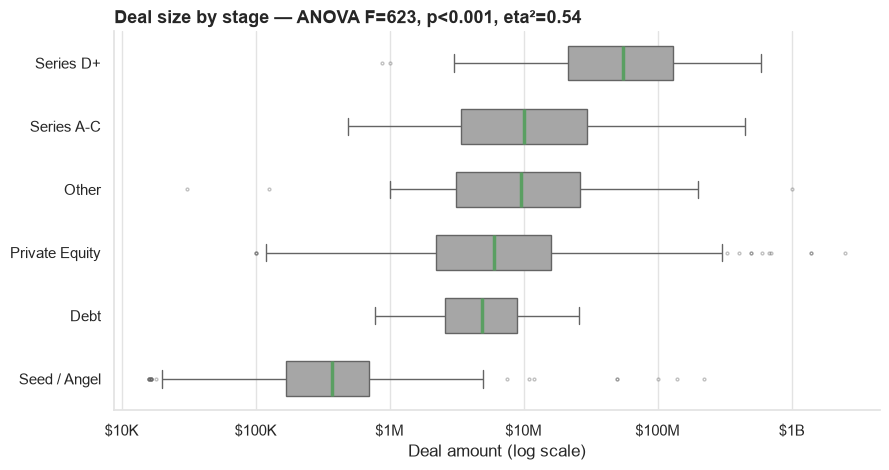

In [14]:
# chart: deal size by stage (log)
order = d.groupby("stage_grp")["log_amount"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=d, y="stage_grp", x="log_amount", order=order, ax=ax, color=GREY, width=0.55,
            flierprops=dict(markersize=2, alpha=0.4), medianprops=dict(color=GREEN, linewidth=2.5))
ax.set_xticks([4, 5, 6, 7, 8, 9], ["$10K", "$100K", "$1M", "$10M", "$100M", "$1B"])
ax.set_xlabel("Deal amount (log scale)"); ax.set_ylabel("")
ax.set_title(f"Deal size by stage — ANOVA F={f_stat:.0f}, p<0.001, eta²={eta_sq:.2f}")
fig.tight_layout()
plt.show()

### 3. A/B TESTING


A/B 1: Does a syndicate (2+ investors) raise more than a single investor?
  A = 1 investor n=1089 rate=29.7%
  B = 2+ investors n=982 rate=40.0%
  Difference B-A = +10.4%; 95% CI +6.3% to +14.4%; lift=+35%
  Two-proportion z=4.95, p=7.4e-07 -> SIGNIFICANT
  Cohen's h=0.22; power=99.9%; minimum detectable effect=+5.8%
  Median deal A=$1.00M vs B=$2.65M; permutation p=0.0000
  Bayesian P(B>A)=100.0%; 95% interval=+6.3% to +14.5%; expected loss=0.00%


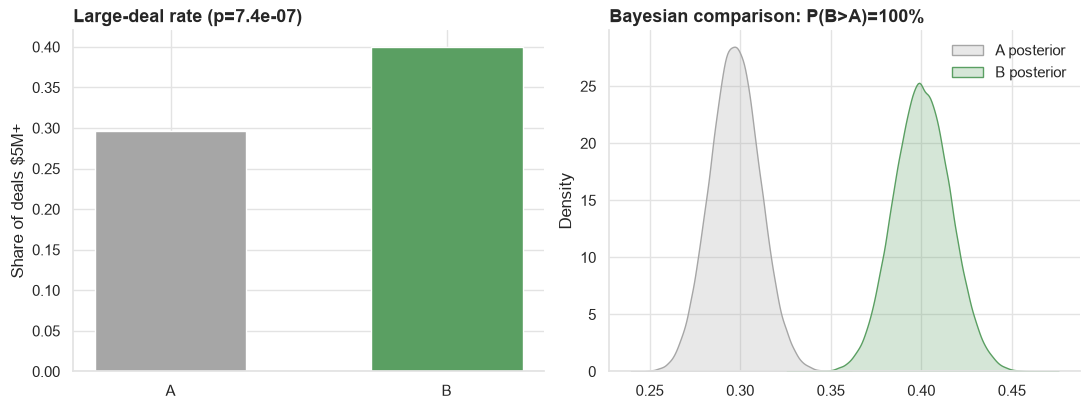


A/B 2: Do Bengaluru startups raise more than the rest of India?
  A = Rest of India n=1338 rate=32.2%
  B = Bengaluru n=595 rate=39.3%
  Difference B-A = +7.1%; 95% CI +2.5% to +11.8%; lift=+22%
  Two-proportion z=3.04, p=2.4e-03 -> SIGNIFICANT
  Cohen's h=0.15; power=85.5%; minimum detectable effect=+6.6%
  Median deal A=$1.50M vs B=$2.30M; permutation p=0.0142
  Bayesian P(B>A)=99.9%; 95% interval=+2.5% to +11.8%; expected loss=0.00%


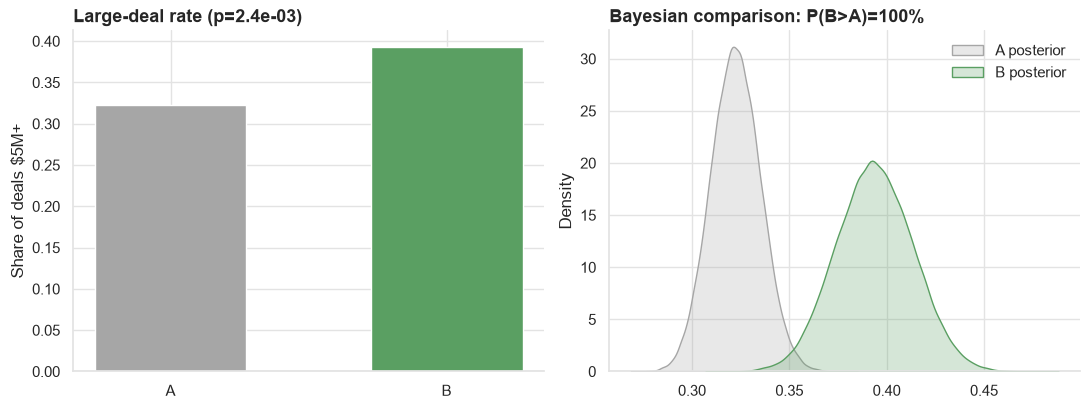

In [15]:
# Run the same A/B analysis for two comparisons using a normal loop.
for test_name, group_column, chart_file in [
    ("A/B 1: Does a syndicate (2+ investors) raise more than a single investor?", "syndicate", "03_ab_syndicate.png"),
    ("A/B 2: Do Bengaluru startups raise more than the rest of India?", "hub", "04_ab_bengaluru.png")
]:
    test_data = d.dropna(subset=[group_column])
    a = test_data[test_data[group_column].str.startswith("A")]
    b = test_data[test_data[group_column].str.startswith("B")]
    na, nb = len(a), len(b)
    ca, cb = a["large_deal"].sum(), b["large_deal"].sum()
    pa, pb = ca / na, cb / nb
    print(f"\n{test_name}")
    print(f"  A = {a[group_column].iloc[0][3:]} n={na} rate={pa:.1%}")
    print(f"  B = {b[group_column].iloc[0][3:]} n={nb} rate={pb:.1%}")
    z, p = proportions_ztest([cb, ca], [nb, na])
    lo, hi = confint_proportions_2indep(cb, nb, ca, na, method="newcomb")
    lift = (pb - pa) / pa
    print(f"  Difference B-A = {pb-pa:+.1%}; 95% CI {lo:+.1%} to {hi:+.1%}; lift={lift:+.0%}")
    print(f"  Two-proportion z={z:.2f}, p={p:.1e} -> {'SIGNIFICANT' if p < ALPHA else 'not significant'}")
    h_obs = 2*np.arcsin(np.sqrt(pb)) - 2*np.arcsin(np.sqrt(pa))
    power = NormalIndPower().power(effect_size=abs(h_obs), nobs1=na, ratio=nb/na, alpha=ALPHA)
    mde_h = NormalIndPower().solve_power(nobs1=na, ratio=nb/na, alpha=ALPHA, power=0.8)
    mde_rate = np.sin(np.arcsin(np.sqrt(pa)) + mde_h/2)**2 - pa
    print(f"  Cohen's h={h_obs:.2f}; power={power:.1%}; minimum detectable effect={mde_rate:+.1%}")
    observed_median_difference = b["amount_usd_mn"].median() - a["amount_usd_mn"].median()
    pooled_values = np.concatenate([a["amount_usd_mn"].values, b["amount_usd_mn"].values])
    permutation_differences = np.empty(5000)
    for shuffle_number in range(5000):
        RNG.shuffle(pooled_values)
        permutation_differences[shuffle_number] = np.median(pooled_values[na:]) - np.median(pooled_values[:na])
    permutation_p = (np.abs(permutation_differences) >= abs(observed_median_difference)).mean()
    print(f"  Median deal A=${a['amount_usd_mn'].median():.2f}M vs B=${b['amount_usd_mn'].median():.2f}M; permutation p={permutation_p:.4f}")
    posterior_a = RNG.beta(1+ca, 1+na-ca, 100000)
    posterior_b = RNG.beta(1+cb, 1+nb-cb, 100000)
    probability_b_better = (posterior_b > posterior_a).mean()
    expected_loss = np.maximum(posterior_a-posterior_b, 0).mean()
    credible_interval = np.percentile(posterior_b-posterior_a, [2.5, 97.5])
    print(f"  Bayesian P(B>A)={probability_b_better:.1%}; 95% interval={credible_interval[0]:+.1%} to {credible_interval[1]:+.1%}; expected loss={expected_loss:.2%}")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    axes[0].bar(["A", "B"], [pa, pb], color=[GREY, GREEN], width=0.55)
    axes[0].set_ylabel("Share of deals $5M+")
    axes[0].set_title(f"Large-deal rate (p={p:.1e})")
    sns.kdeplot(posterior_a, ax=axes[1], color=GREY, fill=True, label="A posterior")
    sns.kdeplot(posterior_b, ax=axes[1], color=GREEN, fill=True, label="B posterior")
    axes[1].set_title(f"Bayesian comparison: P(B>A)={probability_b_better:.0%}")
    axes[1].legend(frameon=False)
    fig.tight_layout()
    plt.show()

In [16]:
print("\n  Caveat: groups were not randomised. Later-stage deals tend to have more investors,")
print("  so part of the syndicate 'lift' may come from stage. Check: stratify the A/B test by stage.")
strata = []
for stg, g in d.dropna(subset=["syndicate"]).groupby("stage_grp"):
    t2 = pd.crosstab(g["syndicate"].str.startswith("B"), g["large_deal"]).reindex(index=[True, False], columns=[1, 0], fill_value=0)
    if (t2.values.sum(axis=1) > 0).all() and t2.values.sum() >= 20:
        strata.append(t2.values + 0.5)          # Haldane correction for empty cells
mh = StratifiedTable(strata)
mh_res = mh.test_null_odds(correction=True)
or_lo, or_hi = mh.oddsratio_pooled_confint()
print(f"  Cochran-Mantel-Haenszel test, stratified by stage ({len(strata)} strata):")
print(f"    pooled odds ratio (B vs A) = {mh.oddsratio_pooled:.2f} (95% CI {or_lo:.2f} - {or_hi:.2f}), "
    f"chi-square = {mh_res.statistic:.2f}, p = {mh_res.pvalue:.1e} -> {'SIGNIFICANT' if mh_res.pvalue < ALPHA else 'not significant'}")
print("    -> Within the same stage, syndicated deals are still more likely to be $5M+." if mh_res.pvalue < ALPHA
    else "    -> Once stage is held fixed, the syndicate effect is no longer significant.")


  Caveat: groups were not randomised. Later-stage deals tend to have more investors,
  so part of the syndicate 'lift' may come from stage. Check: stratify the A/B test by stage.
  Cochran-Mantel-Haenszel test, stratified by stage (5 strata):
    pooled odds ratio (B vs A) = 1.39 (95% CI 1.10 - 1.75), chi-square = 7.50, p = 6.2e-03 -> SIGNIFICANT
    -> Within the same stage, syndicated deals are still more likely to be $5M+.


### 4. REGRESSION

In [17]:
formula = ("log_amount ~ C(stage_grp, Treatment('Seed / Angel')) + C(sector_grp, Treatment('Consumer Internet'))"
           " + C(city_grp, Treatment('Bengaluru')) + year + investor_count")

In [18]:
# --- 4.1 OLS with robust (HC3) errors
ols = smf.ols(formula, data=d).fit(cov_type="HC3")
print(f"4.1 OLS on log10(amount), robust HC3 errors: n = {int(ols.nobs)}, R² = {ols.rsquared:.3f}, "
    f"adj R² = {ols.rsquared_adj:.3f}, AIC = {ols.aic:.0f}")


coefs = pd.DataFrame({"coef": ols.params, "lo": ols.conf_int()[0], "hi": ols.conf_int()[1], "p": ols.pvalues}).drop("Intercept")
coefs["term"] = coefs.index.to_series().astype(str)
coefs["term"] = coefs["term"].str.replace("C(stage_grp, Treatment('Seed / Angel'))[T.", "Stage: ", regex=False)
coefs["term"] = coefs["term"].str.replace("C(sector_grp, Treatment('Consumer Internet'))[T.", "Sector: ", regex=False)
coefs["term"] = coefs["term"].str.replace("C(city_grp, Treatment('Bengaluru'))[T.", "City: ", regex=False)
coefs["term"] = coefs["term"].str.replace("]", "", regex=False)
coefs["term"] = coefs["term"].str.replace("investor_count", "Each extra investor", regex=False)
coefs["term"] = coefs["term"].str.replace("year", "Each later year", regex=False)
coefs["multiplier"] = 10 ** coefs["coef"]
print("    Significant effects (multiplier on deal size vs baseline Seed / Consumer Internet / Bengaluru):")
for _, r in coefs[coefs["p"] < ALPHA].sort_values("coef", ascending=False).iterrows():
    print(f"      {r['term']:<38} x{r['multiplier']:6.2f}   95% CI x{10**r['lo']:.2f} - x{10**r['hi']:.2f}   p={r['p']:.1e}")

4.1 OLS on log10(amount), robust HC3 errors: n = 2072, R² = 0.572, adj R² = 0.567, AIC = 3588
    Significant effects (multiplier on deal size vs baseline Seed / Consumer Internet / Bengaluru):
      Stage: Series D+                       x 47.11   95% CI x19.94 - x111.30   p=1.6e-18
      Stage: Private Equity                  x 16.77   95% CI x14.96 - x18.79   p=0.0e+00
      Stage: Series A-C                      x 12.94   95% CI x8.20 - x20.42   p=3.9e-28
      Stage: Other                           x 10.66   95% CI x3.44 - x33.09   p=4.2e-05
      Stage: Debt                            x  8.40   95% CI x5.75 - x12.26   p=2.9e-28
      Sector: Travel & Hospitality           x  2.76   95% CI x1.56 - x4.89   p=5.2e-04
      Sector: FinTech & Financial Services   x  2.02   95% CI x1.55 - x2.62   p=1.3e-07
      Sector: Logistics & Mobility           x  1.93   95% CI x1.41 - x2.63   p=3.7e-05
      Sector: Real Estate & Home Services    x  1.91   95% CI x1.12 - x3.26   p=1.7e-02
      

In [19]:
# --- 4.2 Multicollinearity (VIF) on the design matrix
X = pd.DataFrame(ols.model.exog, columns=ols.model.exog_names).drop(columns="Intercept")
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=[str(c).replace("investor_count", "Each extra investor").replace("year", "Each later year") for c in X.columns])
print(f"\n4.2 VIF: max = {vif.max():.1f} ({vif.idxmax()}); {(vif > 5).sum()} predictors above 5 "
    f"-> {'multicollinearity is not a concern' if vif.max() < 10 else 'check correlated predictors'}")


4.2 VIF: max = 9.3 (Each later year); 1 predictors above 5 -> multicollinearity is not a concern


4.3 Breusch-Pagan heteroscedasticity p = 3.6e-14 (present -> robust HC3 errors used, as planned)
    Jarque-Bera residual normality p = 1.7e-31, residual skew = 0.35 (n is large, so coefficient tests remain valid)


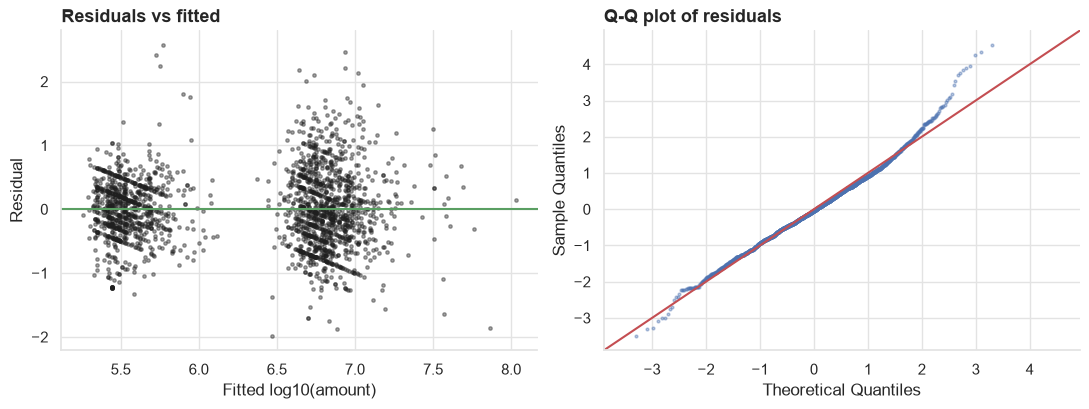

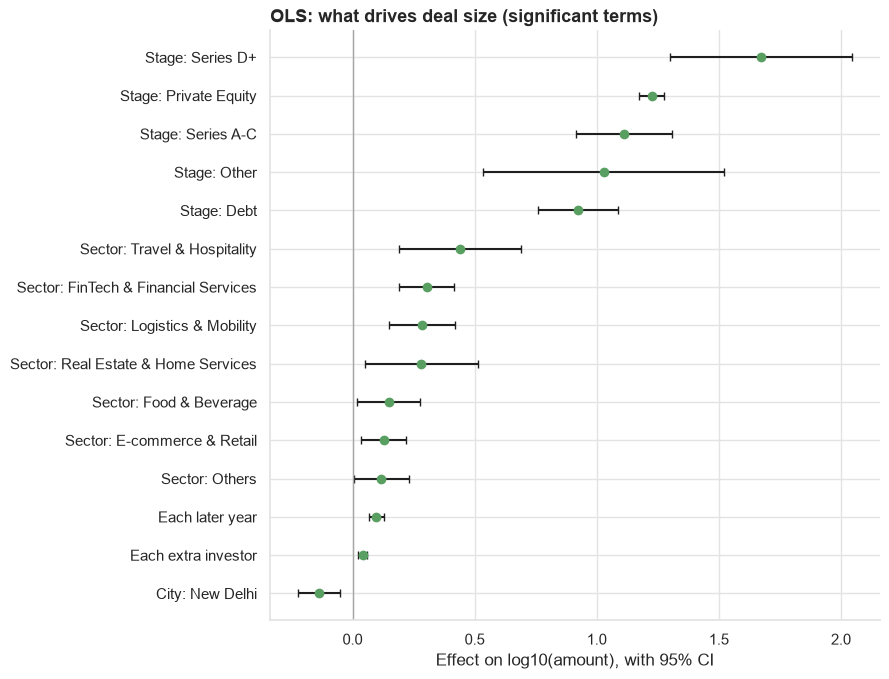

In [20]:
# --- 4.3 Residual diagnostics
bp_lm, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
jb, jb_p = stats.jarque_bera(ols.resid)
print(f"4.3 Breusch-Pagan heteroscedasticity p = {bp_p:.1e} "
    f"({'present -> robust HC3 errors used, as planned' if bp_p < ALPHA else 'not detected'})")
print(f"    Jarque-Bera residual normality p = {jb_p:.1e}, residual skew = {stats.skew(ols.resid):.2f} "
    f"(n is large, so coefficient tests remain valid)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(ols.fittedvalues, ols.resid, s=6, alpha=0.4, color=DARK)
axes[0].axhline(0, color=GREEN, linewidth=1.5)
axes[0].set_title("Residuals vs fitted"); axes[0].set_xlabel("Fitted log10(amount)"); axes[0].set_ylabel("Residual")
sm.qqplot(ols.resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=0.4)
axes[1].set_title("Q-Q plot of residuals")
fig.tight_layout()
plt.show()
sig = coefs[coefs["p"] < ALPHA].sort_values("coef")
fig, ax = plt.subplots(figsize=(9, 0.38 * len(sig) + 1.2))
ax.errorbar(sig["coef"], range(len(sig)), xerr=[sig["coef"] - sig["lo"], sig["hi"] - sig["coef"]],
            fmt="o", color=GREEN, ecolor=DARK, capsize=3)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(range(len(sig)), sig["term"])
ax.set_xlabel("Effect on log10(amount), with 95% CI")
ax.set_title("OLS: what drives deal size (significant terms)")
fig.tight_layout()
plt.show()

In [21]:
# --- 4.4 Quantile regression at the median (robust to outliers)
design = pd.DataFrame(ols.model.exog, columns=ols.model.exog_names)
qreg = QuantileRegressor(quantile=0.5, alpha=0, solver="highs", fit_intercept=False).fit(design, d["log_amount"])
qr_params = pd.Series(qreg.coef_, index=design.columns)
qr_pseudo_r2 = 1 - np.abs(d["log_amount"] - qreg.predict(design)).sum() / np.abs(d["log_amount"] - d["log_amount"].median()).sum()
print(f"\n4.4 Median (quantile 0.5) regression, exact LP solver, robust to mega-round outliers: pseudo R² = {qr_pseudo_r2:.3f}")
for term in ["C(stage_grp, Treatment('Seed / Angel'))[T.Series D+]", "C(stage_grp, Treatment('Seed / Angel'))[T.Private Equity]",
             "C(sector_grp, Treatment('Consumer Internet'))[T.FinTech & Financial Services]", "year"]:
    if term in qr_params:
        print(f"      {str(term).replace("investor_count", "Each extra investor").replace("year", "Each later year"):<38} OLS x{10**ols.params[term]:.2f}   median-reg x{10**qr_params[term]:.2f}")
print("    Series D+ has only 20 disclosed deals, so its median-regression estimate is unstable.")
yr_ols, yr_q = 10 ** ols.params["year"], 10 ** qr_params["year"]
print(f"    Year effect: x{yr_ols:.2f}/year (OLS) vs x{yr_q:.2f}/year (median). " +
    ("Similar, so the typical deal grew, not just the mega-rounds." if abs(yr_ols - yr_q) < 0.1
     else "The gap shows the rise is driven mostly by larger rounds at the top."))


4.4 Median (quantile 0.5) regression, exact LP solver, robust to mega-round outliers: pseudo R² = 0.389
      C(stage_grp, Treatment('Seed / Angel'))[T.Series D+] OLS x47.11   median-reg x70.70
      C(stage_grp, Treatment('Seed / Angel'))[T.Private Equity] OLS x16.77   median-reg x14.55
      C(sector_grp, Treatment('Consumer Internet'))[T.FinTech & Financial Services] OLS x2.02   median-reg x2.07
      Each later year                        OLS x1.25   median-reg x1.23
    Series D+ has only 20 disclosed deals, so its median-regression estimate is unstable.
    Year effect: x1.25/year (OLS) vs x1.23/year (median). Similar, so the typical deal grew, not just the mega-rounds.


In [22]:
# --- 4.5 Logistic regression: odds of a $5M+ deal
logit = smf.logit(formula.replace("log_amount", "large_deal"), data=d).fit(disp=False, maxiter=200)
odds = pd.DataFrame({"OR": np.exp(logit.params), "lo": np.exp(logit.conf_int()[0]),
                     "hi": np.exp(logit.conf_int()[1]), "p": logit.pvalues}).drop("Intercept")
print(f"\n4.5 Logistic regression for P(deal >= $5M): pseudo R² (McFadden) = {logit.prsquared:.3f}, "
    f"LLR p = {logit.llr_pvalue:.1e}")
print("    Significant odds ratios:")
for t_, r in odds[odds["p"] < ALPHA].sort_values("OR", ascending=False).head(8).iterrows():
    print(f"      {str(t_).replace("investor_count", "Each extra investor").replace("year", "Each later year"):<38} OR = {r['OR']:7.2f}  (95% CI {r['lo']:.2f} - {r['hi']:.2f})")


4.5 Logistic regression for P(deal >= $5M): pseudo R² (McFadden) = 0.371, LLR p = 1.6e-192
    Significant odds ratios:
      C(stage_grp, Treatment('Seed / Angel'))[T.Series D+] OR =  211.04  (95% CI 49.30 - 903.46)
      C(stage_grp, Treatment('Seed / Angel'))[T.Private Equity] OR =  128.13  (95% CI 65.43 - 250.90)
      C(stage_grp, Treatment('Seed / Angel'))[T.Series A-C] OR =   93.67  (95% CI 37.19 - 235.92)
      C(stage_grp, Treatment('Seed / Angel'))[T.Debt] OR =   64.22  (95% CI 22.79 - 180.91)
      C(stage_grp, Treatment('Seed / Angel'))[T.Other] OR =   62.96  (95% CI 18.45 - 214.91)
      C(sector_grp, Treatment('Consumer Internet'))[T.Travel & Hospitality] OR =    5.14  (95% CI 1.26 - 21.02)
      C(sector_grp, Treatment('Consumer Internet'))[T.Logistics & Mobility] OR =    3.18  (95% CI 1.67 - 6.04)
      C(sector_grp, Treatment('Consumer Internet'))[T.FinTech & Financial Services] OR =    2.42  (95% CI 1.41 - 4.15)


In [25]:
# Convert funding_date into datetime format
df["funding_date"] = pd.to_datetime(df["funding_date"],errors="coerce")

# Remove rows where funding_date is missing or invalid
df = df.dropna(subset=["funding_date"]).copy()

# Check the datatype
print(df["funding_date"].dtype)

datetime64[us]



4.6 Count model on monthly deals (2015-2019), with month-of-year effects:
    Poisson dispersion = 2.85 -> using Negative Binomial
    Deal count changes x0.66 per year (-34%/year), p = 1.5e-41
    Caution: part of this decline reflects thinner data collection after 2017, not only a cooling market.


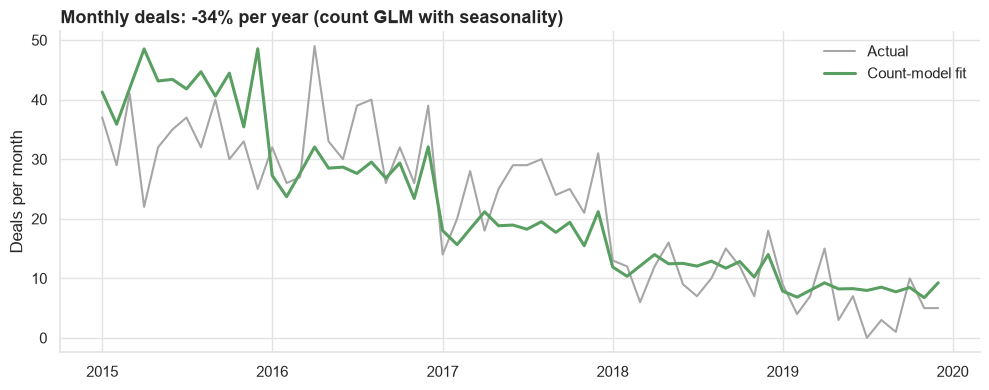

In [26]:
# --- 4.6 Poisson GLM on monthly deal counts
monthly = df.set_index("funding_date").resample("MS")["deal_id"].count().rename("deals").reset_index()
monthly = monthly[monthly["funding_date"] < "2020-01-01"].copy()
monthly["t_years"] = np.arange(len(monthly)) / 12
monthly["month"] = monthly["funding_date"].dt.month
pois = smf.glm("deals ~ t_years + C(month)", data=monthly, family=sm.families.Poisson()).fit()
dispersion = pois.pearson_chi2 / pois.df_resid
negb = smf.glm("deals ~ t_years + C(month)", data=monthly, family=sm.families.NegativeBinomial(alpha=0.05)).fit()
model_c = negb if dispersion > 1.5 else pois
yearly_factor = np.exp(model_c.params["t_years"])
print(f"\n4.6 Count model on monthly deals (2015-2019), with month-of-year effects:")
print(f"    Poisson dispersion = {dispersion:.2f} -> using {'Negative Binomial' if dispersion > 1.5 else 'Poisson'}")
print(f"    Deal count changes x{yearly_factor:.2f} per year ({yearly_factor - 1:+.0%}/year), p = {model_c.pvalues['t_years']:.1e}")
print("    Caution: part of this decline reflects thinner data collection after 2017, not only a cooling market.")
monthly["fitted"] = model_c.fittedvalues
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["funding_date"], monthly["deals"], color=GREY, linewidth=1.5, label="Actual")
ax.plot(monthly["funding_date"], monthly["fitted"], color=GREEN, linewidth=2.2, label="Count-model fit")
ax.set_title(f"Monthly deals: {yearly_factor - 1:+.0%} per year (count GLM with seasonality)")
ax.set_ylabel("Deals per month"); 
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 5. MACHINE LEARNING — predicting a $5M+ deal

In [27]:
cat_cols = ["stage_grp", "sector_grp", "city_grp"]
num_cols = ["year", "investor_count", "is_international_hq", "is_multi_city"]
X, y = d[cat_cols + num_cols], d["large_deal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Rows: train {len(X_train)} / test {len(X_test)}; positive class ($5M+) = {y.mean():.1%}")
print("Features exclude anything derived from the amount itself (no target leakage).")

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                         ("num", StandardScaler(), num_cols)])
pre_dense = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                               ("num", "passthrough", num_cols)])
models = {
    "Dummy (majority)": Pipeline([("pre", pre), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("pre", pre), ("clf", RandomForestClassifier(n_estimators=400, random_state=SEED,
                                                                           class_weight="balanced", n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("pre", pre_dense), ("clf", HistGradientBoostingClassifier(random_state=SEED,
                                                                                              class_weight="balanced"))]),
}

Rows: train 1554 / test 518; positive class ($5M+) = 34.6%
Features exclude anything derived from the amount itself (no target leakage).


In [28]:
# --- 5.1 Tune the Random Forest with GridSearchCV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(models["Random Forest"], {"clf__max_depth": [4, 8, 12, None], "clf__min_samples_leaf": [1, 5, 15]},
                    scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
models["Random Forest"] = grid.best_estimator_
print(f"\n5.1 GridSearchCV (5-fold, ROC-AUC) best Random Forest params: "
    f"{ {k.replace('clf__', ''): v for k, v in grid.best_params_.items()} }, CV AUC = {grid.best_score_:.3f}")


5.1 GridSearchCV (5-fold, ROC-AUC) best Random Forest params: {'max_depth': 4, 'min_samples_leaf': 1}, CV AUC = 0.837


In [29]:
# --- 5.2 Cross-validated comparison
rows = []
for name, m in models.items():
    sc = cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision", "f1", "accuracy"])
    rows.append({"model": name, **{k.replace("test_", "cv_"): f"{v.mean():.3f} ± {v.std():.3f}"
                                    for k, v in sc.items() if k.startswith("test_")}})
cmp_df = pd.DataFrame(rows)
print("\n5.2 Stratified 5-fold cross-validation on the training set:")
print(cmp_df.to_string(index=False))


5.2 Stratified 5-fold cross-validation on the training set:
              model    cv_roc_auc cv_average_precision         cv_f1   cv_accuracy
   Dummy (majority) 0.500 ± 0.000        0.346 ± 0.001 0.000 ± 0.000 0.654 ± 0.001
Logistic Regression 0.824 ± 0.015        0.625 ± 0.023 0.729 ± 0.013 0.750 ± 0.017
      Random Forest 0.837 ± 0.018        0.666 ± 0.028 0.735 ± 0.013 0.754 ± 0.016
  Gradient Boosting 0.827 ± 0.013        0.647 ± 0.012 0.689 ± 0.019 0.742 ± 0.017



5.3 Hold-out test set:
    Dummy (majority)     ROC-AUC = 0.500   average precision = 0.346
    Logistic Regression  ROC-AUC = 0.825   average precision = 0.624
    Random Forest        ROC-AUC = 0.860   average precision = 0.714
    Gradient Boosting    ROC-AUC = 0.850   average precision = 0.670

    Best model: Random Forest. Classification report (test):
                    precision    recall  f1-score   support
      
             < $5M       0.98      0.64      0.78       339
            >= $5M       0.59      0.97      0.73       179
      
          accuracy                           0.76       518
         macro avg       0.78      0.81      0.75       518
      weighted avg       0.84      0.76      0.76       518


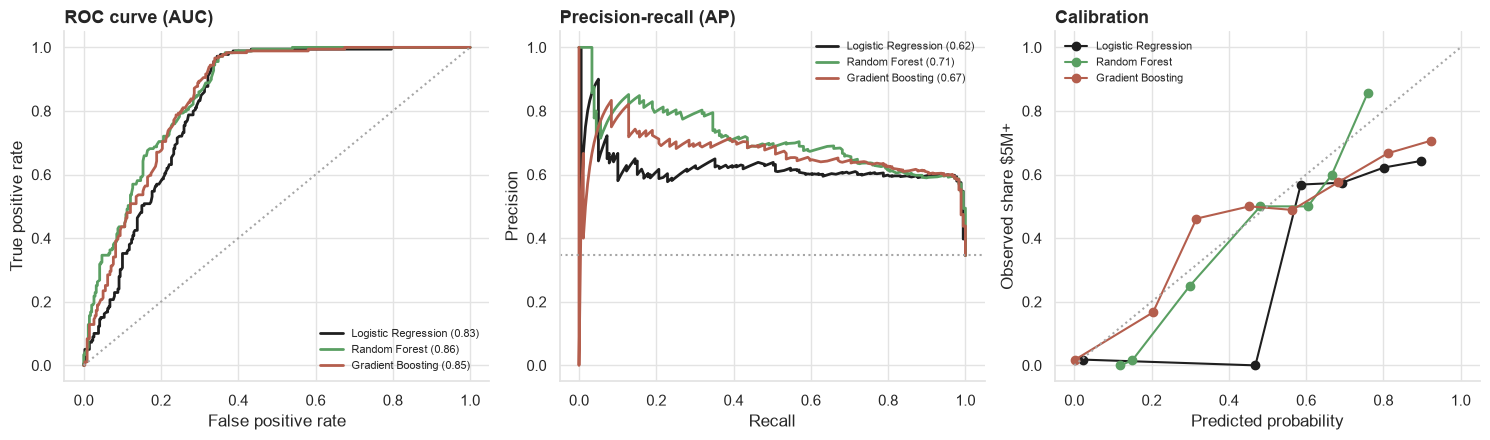

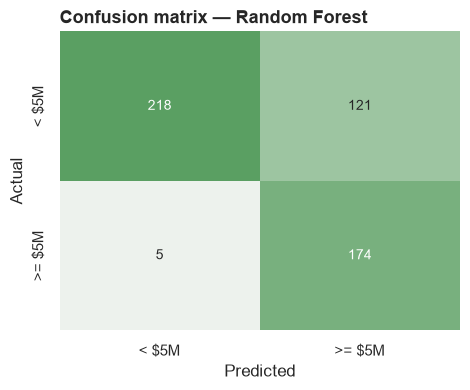

In [30]:
# --- 5.3 Test-set evaluation
print("\n5.3 Hold-out test set:")
test_rows, curves = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    prob = m.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, prob) if name != "Dummy (majority)" else 0.5
    ap = average_precision_score(y_test, prob)
    test_rows.append({"model": name, "test_roc_auc": round(auc, 3), "test_avg_precision": round(ap, 3)})
    curves[name] = prob
    print(f"    {name:<20} ROC-AUC = {auc:.3f}   average precision = {ap:.3f}")
cmp_df = cmp_df.merge(pd.DataFrame(test_rows), on="model")

best_name = max(test_rows, key=lambda r: r["test_roc_auc"])["model"]
best = models[best_name]
pred = best.predict(X_test)
print(f"\n    Best model: {best_name}. Classification report (test):")
for line in classification_report(y_test, pred, target_names=["< $5M", ">= $5M"]).splitlines():
    print("      " + line)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
palette = {"Dummy (majority)": GREY, "Logistic Regression": DARK, "Random Forest": GREEN, "Gradient Boosting": RED}
for name, prob in curves.items():
    if name == "Dummy (majority)":
        continue
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=palette[name], linewidth=2, label=f"{name} ({roc_auc_score(y_test, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rec, prec, color=palette[name], linewidth=2, label=f"{name} ({average_precision_score(y_test, prob):.2f})")
    frac, mean_pred = calibration_curve(y_test, prob, n_bins=8)
    axes[2].plot(mean_pred, frac, marker="o", color=palette[name], label=name)
axes[0].plot([0, 1], [0, 1], ":", color=GREY); axes[0].set_title("ROC curve (AUC)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[1].axhline(y_test.mean(), linestyle=":", color=GREY); axes[1].set_title("Precision-recall (AP)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[2].plot([0, 1], [0, 1], ":", color=GREY); axes[2].set_title("Calibration")
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed share $5M+")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap=sns.light_palette(GREEN, as_cmap=True), cbar=False, ax=ax,
            xticklabels=["< $5M", ">= $5M"], yticklabels=["< $5M", ">= $5M"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix — {best_name}")
fig.tight_layout()
plt.show()


5.4 Permutation importance (drop in test ROC-AUC when a column is shuffled):
      stage_grp            +0.292
      year                 +0.032
      sector_grp           +0.014
      investor_count       +0.011
      city_grp             +0.006
      is_international_hq  +0.001
      is_multi_city        +0.000


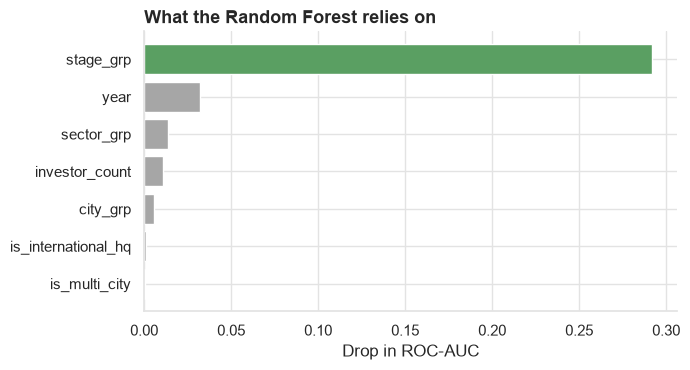

In [31]:
# --- 5.4 Permutation importance on the raw input columns (model-agnostic)
perm = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
print("\n5.4 Permutation importance (drop in test ROC-AUC when a column is shuffled):")
for k, v in imp.sort_values(ascending=False).items():
    print(f"      {k:<20} {v:+.3f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.values, color=[GREEN if v == imp.max() else GREY for v in imp.values])
ax.set_xlabel("Drop in ROC-AUC"); ax.set_title(f"What the {best_name} relies on")
fig.tight_layout()
plt.show()

In [32]:
# --- 5.5 Random Forest regressor for log deal size
rf_reg = Pipeline([("pre", pre), ("reg", RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                                               random_state=SEED, n_jobs=-1))])
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, d["log_amount"], test_size=0.25, random_state=SEED)
rf_reg.fit(Xr_train, yr_train)
yr_pred = rf_reg.predict(Xr_test)
mae = mean_absolute_error(yr_test, yr_pred)
print(f"\n5.5 Random Forest regressor on log10(amount): test R² = {r2_score(yr_test, yr_pred):.3f}, "
    f"MAE = {mae:.2f} log units (a typical prediction is within x{10**mae:.1f} of the actual amount)")


5.5 Random Forest regressor on log10(amount): test R² = 0.587, MAE = 0.44 log units (a typical prediction is within x2.7 of the actual amount)


### 6. CLUSTERING — segmenting sectors with K-Means

C:\Users\HARSHIT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HARSHIT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HARSHIT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HARSHIT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak o

Silhouette score by k: k=2: 0.41, k=3: 0.34, k=4: 0.29, k=5: 0.30  -> k = 2
  Cluster 0: Consumer Internet, E-commerce & Retail, EdTech, Food & Beverage, HealthTech & Wellness, Media & Entertainment, Others, Real Estate & Home Services, Technology, SaaS & IT, Travel & Hospitality
    avg median deal $1.7M, large-deal share 32%, deal-share change -0.3 pts
  Cluster 1: FinTech & Financial Services, Logistics & Mobility
    avg median deal $5.5M, large-deal share 54%, deal-share change +5.9 pts


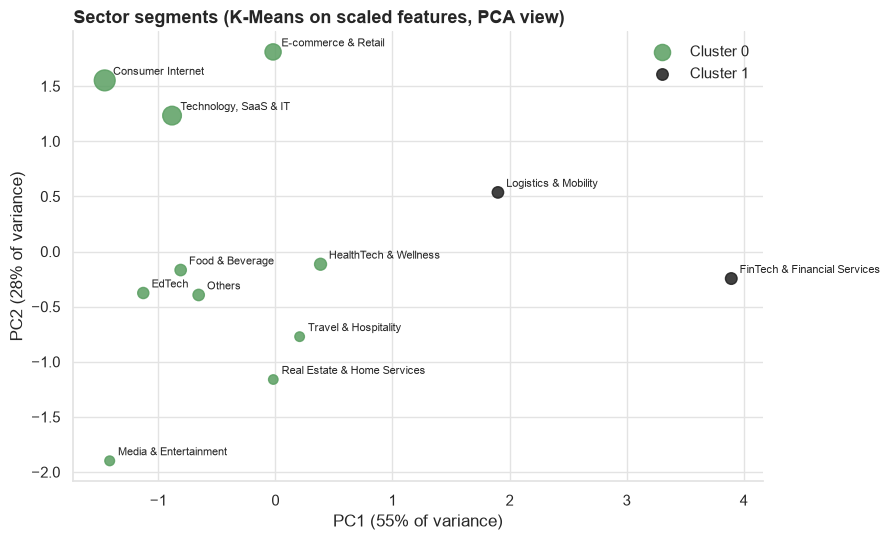

In [33]:
early, late = df[df["year"].isin([2015, 2016])], df[df["year"].isin([2018, 2019])]
seg = pd.DataFrame({
    "deals": df.groupby("sector")["deal_id"].count(),
    "median_deal_mn": d.groupby("sector")["amount_usd_mn"].median(),
    "large_deal_share": d.groupby("sector")["large_deal"].mean(),
    "share_change_pts": (late["sector"].value_counts(normalize=True) - early["sector"].value_counts(normalize=True)) * 100,
}).drop(index="Unknown", errors="ignore").dropna()
seg["log_deals"] = np.log10(seg["deals"])
features = ["log_deals", "median_deal_mn", "large_deal_share", "share_change_pts"]
Z = StandardScaler().fit_transform(seg[features])

scores = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 6)}
k_best = max(scores, key=scores.get)
seg["cluster"] = KMeans(k_best, n_init=20, random_state=SEED).fit_predict(Z)
print("Silhouette score by k: " + ", ".join(f"k={k}: {v:.2f}" for k, v in scores.items()) + f"  -> k = {k_best}")
for c, g in seg.groupby("cluster"):
    print(f"  Cluster {c}: {', '.join(g.index)}")
    print(f"    avg median deal ${g['median_deal_mn'].mean():.1f}M, large-deal share {g['large_deal_share'].mean():.0%}, "
        f"deal-share change {g['share_change_pts'].mean():+.1f} pts")

pcs = PCA(2, random_state=SEED).fit(Z)
P = pcs.transform(Z)
fig, ax = plt.subplots(figsize=(9, 5.5))
cols = [GREEN, DARK, RED, GREY, "#8B7968"]
for c in sorted(seg["cluster"].unique()):
    m = seg["cluster"].values == c
    ax.scatter(P[m, 0], P[m, 1], s=seg["deals"].values[m] / 2 + 40, color=cols[c], alpha=0.85, label=f"Cluster {c}")
for i, name in enumerate(seg.index):
    ax.annotate(name, (P[i, 0], P[i, 1]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Sector segments (K-Means on scaled features, PCA view)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### SUMMARY

In [35]:
print(f"Best classifier: {best_name} (test ROC-AUC {max(r['test_roc_auc'] for r in test_rows):.3f}).")
print('All charts and tables were displayed in the notebook. No output files were saved.')

Best classifier: Random Forest (test ROC-AUC 0.860).
All charts and tables were displayed in the notebook. No output files were saved.
